# Trabajo Práctico N° 2: árboles de decisión, Bayes Ingenuo y k-NN

- Año: 2026
- Materia: Minería de Datos
- Integrantes: Frank, Maximiliano; Winter, Federico

Todas las particiones y todos los modelos usan random_state=63.

In [1]:
# Librerías y semilla
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from feature_engine.outliers import Winsorizer

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, KBinsDiscretizer
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (mean_absolute_error, mean_squared_error, accuracy_score,
                             precision_score, recall_score, ConfusionMatrixDisplay)

SEED = 63  # random_state de todas las particiones y modelos


# Agrega "Figura n" debajo del gráfico.
def numerar(n):
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    plt.figtext(0.5, 0.01, f"Figura {n}", ha="center", va="bottom")


# Dibuja una matriz de correlación como mapa de calor, con su título y número de figura.
def plot_correlation_heatmap(corr, title, n):
    ax = sns.heatmap(corr, vmin=-1, vmax=1, center=0,
                     cmap=sns.diverging_palette(20, 220, n=200),
                     square=True, annot=True, annot_kws={'size': 8})
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment='right')
    plt.title(title)
    numerar(n)
    plt.show()


# Devuelve Precision y Recall macro (promedio simple entre clases) y Accuracy.
def metricas(y, pred):
    return {"Precision macro": precision_score(y, pred, average="macro", zero_division=0),
            "Recall macro": recall_score(y, pred, average="macro", zero_division=0),
            "Accuracy": accuracy_score(y, pred)}


# Dibuja una matriz de confusión por cada (y real, y predicho, título) de la lista.
def plot_cms(items, titulo, n):
    fig, axes = plt.subplots(1, len(items), figsize=(5.5 * len(items), 4.8))
    for ax, (y, p, t) in zip(np.atleast_1d(axes), items):
        ConfusionMatrixDisplay.from_predictions(y, p, ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(t)
    plt.suptitle(titulo)
    numerar(n)
    plt.show()

# Parte A: regresión (1000_Companies.csv)

## Descripción de las variables de 1000_Companies.csv

El conjunto tiene 1000 filas, una por empresa, y 5 columnas: tres variables de gasto, una de ubicación y el resultado económico. La variable objetivo es Profit. El archivo no indica la unidad monetaria de los montos.

| Variable | Qué representa | Tipo | Rol |
|---|---|---|---|
| RyD_Spend | Gasto de la empresa en investigación y desarrollo | Numérica continua | Predictora |
| Administration | Gasto de la empresa en administración | Numérica continua | Predictora |
| MarketingSpend | Gasto de la empresa en marketing | Numérica continua | Predictora |
| State | Estado donde opera la empresa (California, Florida o New York) | Categórica nominal | Predictora |
| Profit | Beneficio de la empresa | Numérica continua | Objetivo (regresión) |

## Actividad 1. Preparación de datos

Consigna: hacer el EDA (distribuciones, faltantes, correlaciones), limpiar el conjunto, codificar las categóricas, estandarizar las numéricas y generar las particiones 80/20 y 70/30 con random_state=63.

Seguimos el orden de la consigna: EDA sobre el conjunto completo, limpieza y partición. Los codificadores y el estandarizador se ajustan solo con train, para evitar fuga de datos. Empezamos por la estructura, los nulos, los duplicados y las categorías.

In [2]:
# Estructura y descriptivas
df = pd.read_csv("1000_Companies.csv")
display(df.head())
df.info()

,RyD_Spend,Administration,MarketingSpend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   RyD_Spend       1000 non-null   float64
 1   Administration  1000 non-null   float64
 2   MarketingSpend  1000 non-null   float64
 3   State           1000 non-null   str    
 4   Profit          1000 non-null   float64
dtypes: float64(4), str(1)
memory usage: 39.2 KB


In [3]:
# Categóricas y nulos
print("Columnas con nulos:", df.isna().any().sum())
print("Filas duplicadas:", df.duplicated().sum())
display(df[df.duplicated(keep=False)])
print("\nCeros por columna numérica:")
print((df.select_dtypes("number") == 0).sum().to_string())
print("\nState:")
print(df["State"].value_counts().to_string())
df.describe()

Columnas con nulos: 0
Filas duplicadas: 1


,RyD_Spend,Administration,MarketingSpend,State,Profit
335,84533.0,122941.3141,231885.6935,California,121248.7116
755,84533.0,122941.3141,231885.6935,California,121248.7116



Ceros por columna numérica:
RyD_Spend         2
Administration    0
MarketingSpend    3
Profit            0

State:
State
California    344
New York      334
Florida       322


,RyD_Spend,Administration,MarketingSpend,Profit
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,81668.927200,122963.897612,226205.058419,119546.164656
std,46537.567891,12613.927535,91578.393542,42888.633848
min,0.000000,51283.140000,0.000000,14681.400000
25%,43084.500000,116640.684850,150969.584600,85943.198543
50%,79936.000000,122421.612150,224517.887350,117641.466300
75%,124565.500000,129139.118000,308189.808525,155577.107425
max,165349.200000,321652.140000,471784.100000,476485.430000


Resultado de la inspección: el conjunto tiene 1000 filas y 5 columnas, sin valores faltantes. Hay una fila duplicada (filas 335 y 755). State tiene tres categorías parejas (California 344, New York 334, Florida 322). RyD_Spend tiene 2 ceros y MarketingSpend tiene 3. El máximo de Profit (476485) está muy lejos de su mediana (117641).

Hipótesis previa: esperamos que Profit crezca con RyD_Spend y con MarketingSpend, que Administration tenga una relación débil con Profit y que State influya poco. Esperamos también que RyD_Spend y MarketingSpend estén correlacionadas entre sí. Los gráficos siguientes ponen a prueba esta hipótesis.

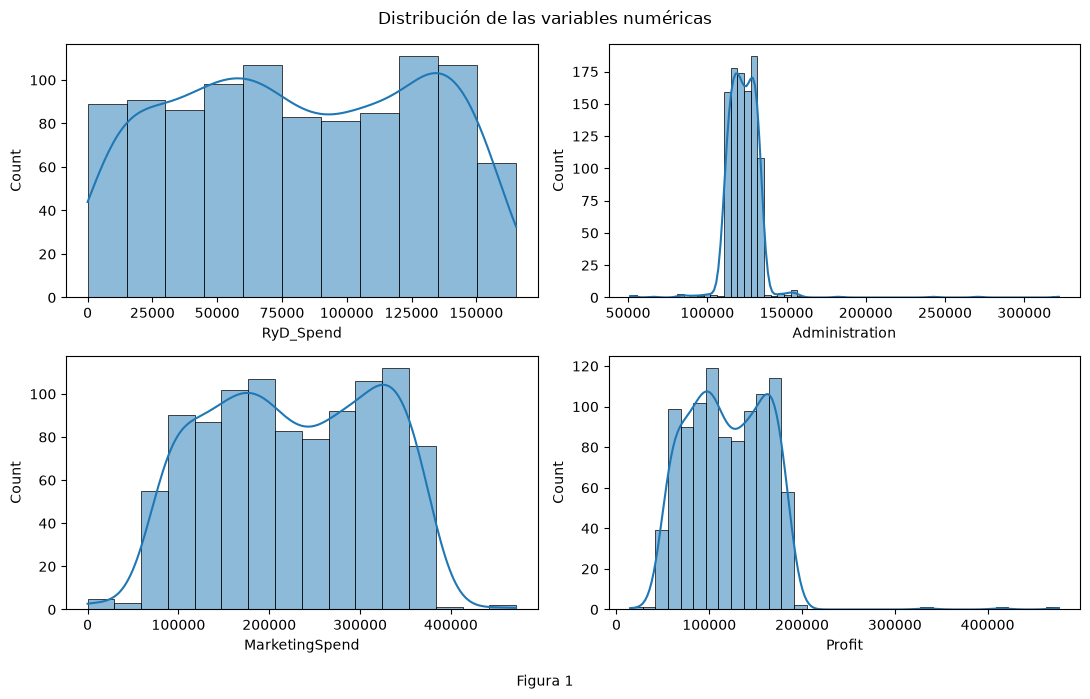

In [4]:
# Histogramas
num_cols = ["RyD_Spend", "Administration", "MarketingSpend", "Profit"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for col, ax in zip(num_cols, axes.flatten()):
    sns.histplot(data=df, x=col, kde=True, edgecolor="black", linewidth=0.5, ax=ax)
plt.suptitle("Distribución de las variables numéricas")
numerar(1)
plt.show()

Figura 1. RyD_Spend va de 0 a 165349 y MarketingSpend de 0 a 471784, con la mayoría de sus valores entre unos 60000 y 400000. Administration se concentra entre 100000 y 150000 y tiene valores aislados hasta 321652. Profit se concentra entre unos 40000 y 190000 y tiene una cola hasta 476485. La cola de Profit y los valores aislados de Administration son candidatos a atípicos. La figura describe cada variable por separado y no permite probar la hipótesis, que trata de relaciones entre variables.

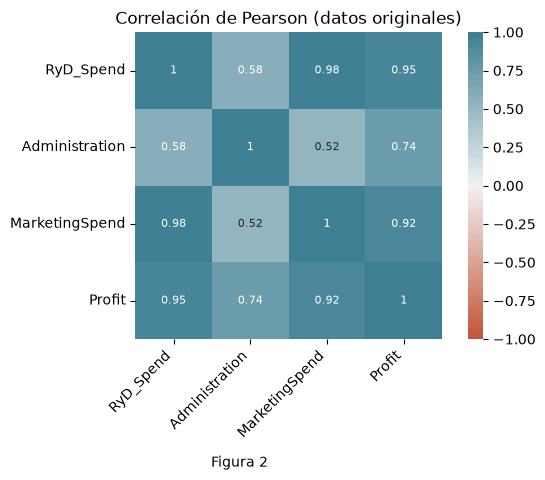

In [5]:
# Matriz de correlación
plot_correlation_heatmap(df[num_cols].corr(), "Correlación de Pearson (datos originales)", 2)

Figura 2. Profit tiene correlación de Pearson de 0.95 con RyD_Spend, 0.92 con MarketingSpend y 0.74 con Administration. RyD_Spend y MarketingSpend tienen 0.98 entre sí.

La hipótesis se cumple para RyD_Spend y MarketingSpend, y para la correlación entre ambas. No se cumple para Administration: su correlación es moderada y no débil. Como RyD_Spend y MarketingSpend aportan información casi igual, esperamos que el árbol use una de las dos en los primeros cortes.

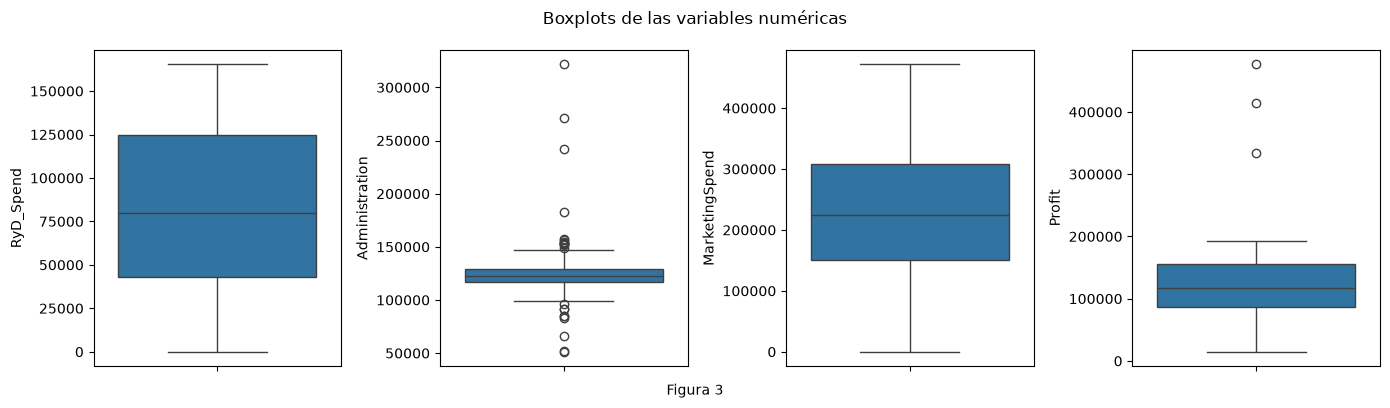

RyD_Spend: 0 atípicos (0.0%), límites [-79137, 246787]
Administration: 22 atípicos (2.2%), límites [97893, 147887]
MarketingSpend: 0 atípicos (0.0%), límites [-84861, 544020]
Profit: 3 atípicos (0.3%), límites [-18508, 260028]


In [6]:
# Boxplots y conteo de atípicos por IQR
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for col, ax in zip(num_cols, axes):
    sns.boxplot(y=df[col], ax=ax)
plt.suptitle("Boxplots de las variables numéricas")
numerar(3)
plt.show()

for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, up = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[col] < low) | (df[col] > up)).sum()
    print(f"{col}: {n} atípicos ({n / len(df) * 100:.1f}%), límites [{low:.0f}, {up:.0f}]")

Figura 3. El conteo por IQR da 0 atípicos en RyD_Spend, 0 en MarketingSpend, 22 en Administration (2.2%) y 3 en Profit (0.3%). Antes de borrar, revisamos si esas filas siguen el comportamiento del resto de los datos.

,RyD_Spend,Administration,MarketingSpend,State,Profit
997,100275.47,241926.31,227142.82,California,413956.48
998,128456.23,321652.14,281692.32,California,333962.19
999,161181.72,270939.86,295442.17,New York,476485.43


Atípicos de Administration fuera de las 3 filas anómalas: 19, índice máximo 48
Profit de esas filas: 35673.0 a 191792.0


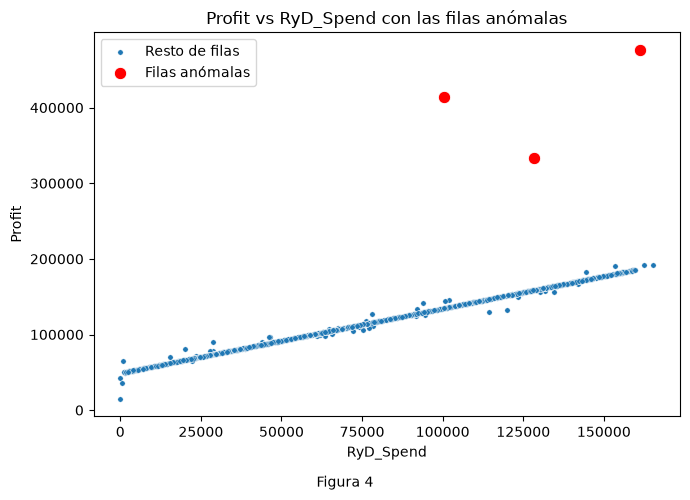

In [7]:
# Filas con Profit fuera del límite IQR
q1, q3 = df["Profit"].quantile([0.25, 0.75])
anomalas = df[(df["Profit"] > q3 + 1.5 * (q3 - q1)) | (df["Profit"] < q1 - 1.5 * (q3 - q1))]
display(anomalas)

# Atípicos de Administration: revisar si pertenecen al comportamiento del resto antes de borrar
qa1, qa3 = df["Administration"].quantile([0.25, 0.75])
adm = df[((df["Administration"] > qa3 + 1.5 * (qa3 - qa1)) | (df["Administration"] < qa1 - 1.5 * (qa3 - qa1)))
         & ~df.index.isin(anomalas.index)]
print(f"Atípicos de Administration fuera de las 3 filas anómalas: {len(adm)}, índice máximo {adm.index.max()}")
print("Profit de esas filas:", adm["Profit"].min().round(0), "a", adm["Profit"].max().round(0))

# Comparación original vs limpio
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df, x="RyD_Spend", y="Profit", s=15, ax=ax, label="Resto de filas")
sns.scatterplot(data=anomalas, x="RyD_Spend", y="Profit", color="red", s=80, ax=ax, label="Filas anómalas")
plt.title("Profit vs RyD_Spend con las filas anómalas")
numerar(4)
plt.show()

Figura 4. Profit sigue una recta casi perfecta con RyD_Spend, como anticipaba la hipótesis. Las tres filas marcadas en rojo (997, 998 y 999) quedan muy por encima de la recta. Tienen Profit de 413956, 333962 y 476485, entre 1.7 y 2.5 veces el máximo del resto (192262), y Administration de 241926, 321652 y 270940, por encima del máximo del resto (182646). Son los únicos atípicos de Profit por IQR.

Los otros 19 atípicos de Administration están entre las primeras 50 filas del archivo (índice máximo 48) y tienen Profit entre 35673 y 191792, dentro del rango del resto. Esas filas siguen la relación con RyD_Spend.

In [8]:
df_clean = df.drop(index=anomalas.index).drop_duplicates()
print("Filas:", len(df), "->", len(df_clean))
print("Correlación de Pearson con Profit:")
print(pd.DataFrame({"original": df[num_cols].corr()["Profit"], "limpio": df_clean[num_cols].corr()["Profit"]}).round(3))
print("Máximos después de limpiar:")
print(df_clean[num_cols].max().to_string())

Filas: 1000 -> 996
Correlación de Pearson con Profit:
                original  limpio
RyD_Spend          0.945   0.999
Administration     0.742   0.745
MarketingSpend     0.917   0.981
Profit             1.000   1.000
Máximos después de limpiar:
RyD_Spend         165349.20
Administration    182645.56
MarketingSpend    471784.10
Profit            192261.83


Decisiones de limpieza:

- Eliminamos las 3 filas anómalas. No siguen la relación que cumplen las demás filas (Figura 4) y son los únicos atípicos de Profit.
- Conservamos los 19 atípicos restantes de Administration, porque su Profit es coherente con el resto.
- Conservamos los ceros de RyD_Spend y MarketingSpend, que son valores de gasto posibles. No hay nulos para imputar.
- Eliminamos la fila duplicada. Si una copia cae en train y la otra en test, el test incluye un ejemplo ya visto.

El conjunto pasa de 1000 a 996 filas. Después de limpiar, la correlación de Profit con RyD_Spend sube de 0.945 a 0.999 y con MarketingSpend de 0.917 a 0.981. Con Administration casi no cambia (0.742 a 0.745), por lo que su correlación moderada no depende de las tres filas eliminadas.

In [9]:
# Partición con random_state=63 y dos proporciones
X = df_clean.drop(columns="Profit")
y = df_clean["Profit"]
particiones = {}
for nombre, ts in [("80/20", 0.2), ("70/30", 0.3)]:
    particiones[nombre] = train_test_split(X, y, test_size=ts, random_state=SEED)
    print(nombre, "-> train:", len(particiones[nombre][0]), "| test:", len(particiones[nombre][1]))

80/20 -> train: 796 | test: 200


70/30 -> train: 697 | test: 299


In [10]:
# Codificación de State (OneHotEncoder) y estandarización de las numéricas (StandardScaler), ajustadas solo con train
num_X = ["RyD_Spend", "Administration", "MarketingSpend"]
# State va primero: RyD_Spend y MarketingSpend casi empatan como corte y el orden de columnas decide el desempate
prep = ColumnTransformer([("cat", OneHotEncoder(sparse_output=False), ["State"]),
                          ("num", StandardScaler(), num_X)],
                         verbose_feature_names_out=False).set_output(transform="pandas")

datos = {}
for nombre, (Xtr, Xte, ytr, yte) in particiones.items():
    datos[nombre] = (prep.fit_transform(Xtr), prep.transform(Xte))   # fit solo con train

# Comprobación en la partición 80/20: columnas resultantes
Xtr_s, Xte_s = datos["80/20"]
display(Xtr_s.head())

,State_California,State_Florida,State_New York,RyD_Spend,Administration,MarketingSpend
398,1.0,0.0,0.0,-1.482993,-1.147181,-1.452454
794,1.0,0.0,0.0,-1.479694,-1.144655,-1.449217
102,0.0,1.0,0.0,1.015917,0.766041,0.999432
883,1.0,0.0,0.0,-0.351660,-0.281007,-0.342410
219,1.0,0.0,0.0,-1.518898,-1.174670,-1.487683


Particiones con random_state=63: el 80/20 deja 796 filas de train y 200 de test, y el 70/30 deja 697 y 299.

Codificación y estandarización, paso a paso:

- **Codificación de State.** Los modelos trabajan con números y State es texto. Sus tres categorías (California, Florida y New York) no tienen un orden natural, por lo que usamos OneHotEncoder. Crea una columna 0/1 por estado (State_California, State_Florida y State_New York): cada fila tiene un 1 en la columna de su estado y 0 en las otras dos. Un código 0, 1, 2 impondría un orden entre estados que no existe.
- **Estandarización de las numéricas.** StandardScaler resta a cada variable su media y la divide por su desvío, de modo que RyD_Spend, Administration y MarketingSpend quedan con media 0 y desvío 1. La consigna lo pide y deja a las tres en la misma escala (RyD_Spend llega a 165349 y MarketingSpend a 471784). Un árbol no lo necesita, porque solo compara cada valor contra un umbral. Sí importa en los modelos que usan distancias, como k-NN. Profit es la variable objetivo y no se transforma.
- **Ajuste solo con train.** El ajuste (fit) calcula la media y el desvío con las filas de train, y la transformación (transform) los aplica a train y a test. Si se calcularan con todos los datos, el test influiría en el preprocesamiento (fuga de datos).
- **Qué queda para modelar.** ColumnTransformer aplica las dos transformaciones juntas y devuelve una tabla por partición con las columnas State_California, State_Florida, State_New York, RyD_Spend, Administration y MarketingSpend. La Actividad 2 entrena y grafica el árbol con estas tablas, por lo que los umbrales de las Figuras 5 y 6 están en unidades estandarizadas.

## Actividad 2. Árboles de decisión para regresión

Consigna: estimar Profit con DecisionTreeRegressor, explorar max_depth, min_samples_leaf y min_samples_split con al menos 3 valores cada uno, justificar el mejor modelo, graficar el árbol y reportar MAE, MSE y RMSE en ambos test.

La grilla tiene max_depth con 3 valores (3, 5, 10), min_samples_split con 3 (2, 5, 10) y min_samples_leaf con 3 (1, 5, 10). Son 27 combinaciones. Elegimos por validación cruzada de 5 folds sobre train, con el RMSE como criterio, la misma métrica que reportamos en test. Así el test no interviene en la elección.

Hipótesis previa: el primer corte será por RyD_Spend, la variable más correlacionada con Profit, y MarketingSpend aparecerá después. Como la relación es casi lineal, esperamos un árbol de profundidad media que la aproxime con escalones.

In [11]:
# Grilla de hiperparámetros con GridSearchCV; el criterio es el RMSE, la misma métrica que se reporta en test
# Selección por validación cruzada de 5 folds sobre train, porque el TP solo define train y test
param_grid = {"max_depth": [3, 5, 10],
              "min_samples_split": [2, 5, 10],
              "min_samples_leaf": [1, 5, 10]}

grids_A = {}
for nombre in particiones:
    Xtr = datos[nombre][0]
    grids_A[nombre] = GridSearchCV(DecisionTreeRegressor(random_state=SEED), param_grid, cv=5,
                                   scoring="neg_root_mean_squared_error").fit(Xtr, particiones[nombre][2])
    g = grids_A[nombre]
    res = pd.DataFrame(g.cv_results_)
    res["RMSE (CV)"] = -res["mean_test_score"]
    print(f"Partición {nombre}: mejor = {g.best_params_}, profundidad real = {g.best_estimator_.get_depth()}, "
          f"hojas = {g.best_estimator_.get_n_leaves()}")
    display(res.sort_values("RMSE (CV)")[["param_max_depth", "param_min_samples_split", "param_min_samples_leaf",
                                         "RMSE (CV)"]].head(8).round(0))

Partición 80/20: mejor = {'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2}, profundidad real = 8, hojas = 130


,param_max_depth,param_min_samples_split,param_min_samples_leaf,RMSE (CV)
23,10,10,5,1824.0
21,10,2,5,1824.0
22,10,5,5,1824.0
24,10,2,10,2056.0
26,10,10,10,2056.0
25,10,5,10,2056.0
20,10,10,1,2195.0
18,10,2,1,2373.0


Partición 70/30: mejor = {'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2}, profundidad real = 8, hojas = 106


,param_max_depth,param_min_samples_split,param_min_samples_leaf,RMSE (CV)
23,10,10,5,2167.0
21,10,2,5,2167.0
22,10,5,5,2167.0
24,10,2,10,2305.0
26,10,10,10,2305.0
25,10,5,10,2305.0
14,5,10,5,2475.0
12,5,2,5,2475.0


En las dos particiones gana la misma configuración: max_depth=10, min_samples_leaf=5 y min_samples_split=2. Su RMSE de validación es 1824 en la partición 80/20 y 2167 en la 70/30. Hay 3 configuraciones empatadas en el primer lugar en cada partición, y GridSearchCV devuelve la primera. El empate tiene una causa: con min_samples_leaf=5, un nodo necesita al menos 10 observaciones para dividirse, por lo que min_samples_split=2, 5 y 10 producen el mismo árbol.

Efecto de max_depth y min_samples_leaf en el top 8 de la tabla:

- max_depth: las 8 mejores configuraciones usan max_depth=10, salvo dos del 70/30 que usan max_depth=5 (RMSE 2475). max_depth=3 no aparece, porque un árbol tan chico no alcanza a seguir la relación (subajuste).
- min_samples_leaf: con 5 el RMSE es el menor. Con 10 sube a 2056 y 2305, porque las hojas grandes pierden detalle. Con 1 el árbol se ajusta al ruido. En el 80/20 aparece después de las de 10 (RMSE 2195 y 2373) y en el 70/30 queda fuera del top 8.

Elegimos max_depth=10, min_samples_leaf=5 y min_samples_split=2. El árbol resultante tiene profundidad 8 y 130 hojas en el 80/20, y 106 hojas en el 70/30.

In [12]:
# MAE, MSE y RMSE sobre ambos conjuntos de test
preds_A, filas = {}, {}
for nombre, g in grids_A.items():
    yte = particiones[nombre][3]
    preds_A[nombre] = g.predict(datos[nombre][1])   # GridSearchCV predice con el mejor árbol
    mse = mean_squared_error(yte, preds_A[nombre])
    filas[nombre] = {"MAE": mean_absolute_error(yte, preds_A[nombre]), "MSE": mse, "RMSE": np.sqrt(mse)}
tabla_A = pd.DataFrame(filas).T.rename_axis("Partición")
display(tabla_A.round(1))

,MAE,MSE,RMSE
Partición,,,
80/20,1098.9,12222722.2,3496.1
70/30,942.6,8579615.4,2929.1


Resultados sobre test:

- Partición 80/20: MAE 1098.9, MSE 12222722.2 y RMSE 3496.1.
- Partición 70/30: MAE 942.6, MSE 8579615.4 y RMSE 2929.1.

El MAE equivale a alrededor del 1% de una mediana de Profit de 117641. El RMSE es mucho mayor que el MAE (3496.1 contra 1098.9), lo que indica que hay unos pocos errores grandes, que el RMSE penaliza más.

El RMSE del 70/30 es menor que el del 80/20 aunque entrena con menos datos. Los dos test son muestras distintas (200 y 299 filas), por lo que esa diferencia no alcanza para decir que una partición es mejor.

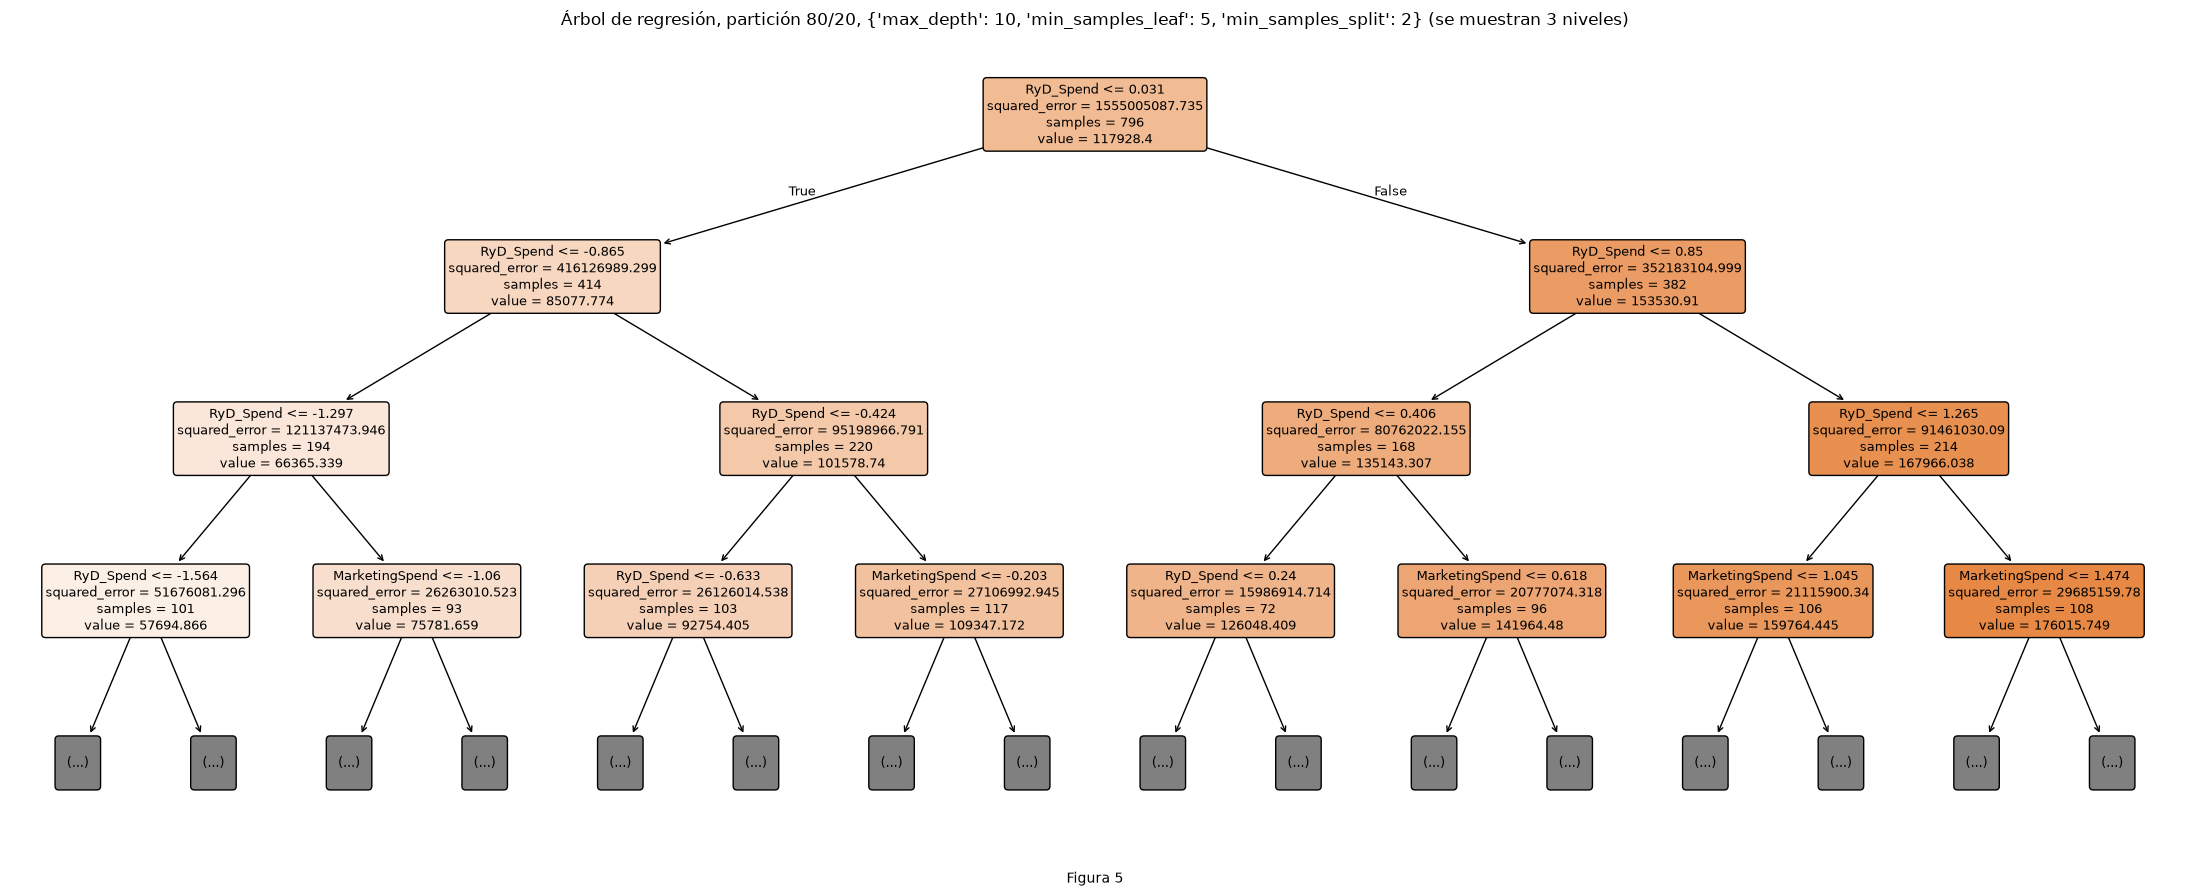

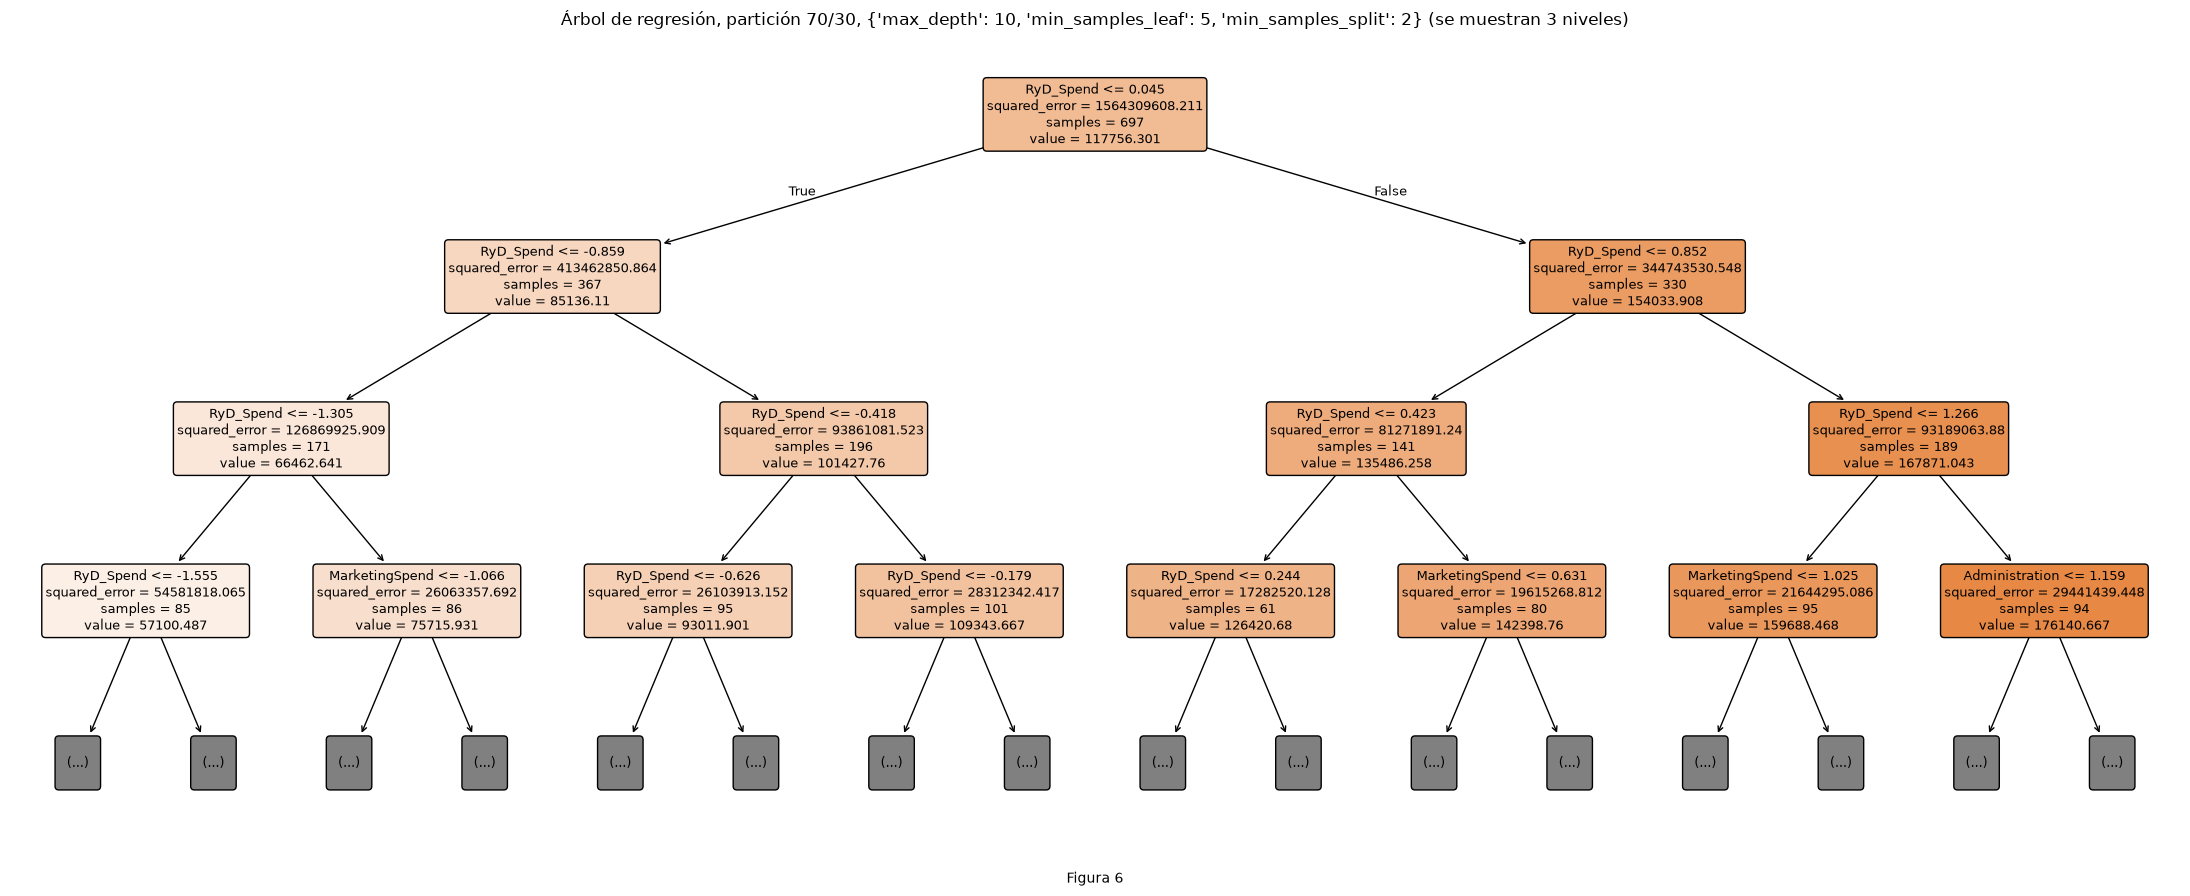

In [13]:
# plot_tree con max_depth=3 para que se lea
for i, (nombre, g) in enumerate(grids_A.items(), 1):
    plt.figure(figsize=(22, 9))
    plot_tree(g.best_estimator_, feature_names=list(datos[nombre][0].columns),
              filled=True, rounded=True, max_depth=3, fontsize=9)
    plt.title(f"Árbol de regresión, partición {nombre}, {g.best_params_} (se muestran 3 niveles)")
    numerar(4 + i)
    plt.show()

Figuras 5 y 6. Los árboles se entrenan con las variables estandarizadas, por lo que los umbrales están en desvíos respecto de la media de train. Graficamos cada árbol hasta max_depth=3, porque los árboles completos tienen 130 y 106 hojas y no se leen. La raíz divide por RyD_Spend en 0.031 en el 80/20 y en 0.045 en el 70/30 (82150.5 y 82618 en unidades originales). El valor medio de Profit pasa de 85078 en la rama izquierda a 153531 en la derecha del 80/20. La raíz y los dos niveles siguientes dividen siempre por RyD_Spend. En el cuarto nivel de nodos aparece MarketingSpend en ambos árboles, y Administration en un nodo del 70/30. State no aparece en los niveles mostrados.

Esto es coherente con la hipótesis. RyD_Spend es la variable más correlacionada con Profit (0.999 después de limpiar) y MarketingSpend aparece después. Administration, con correlación moderada, casi no interviene.

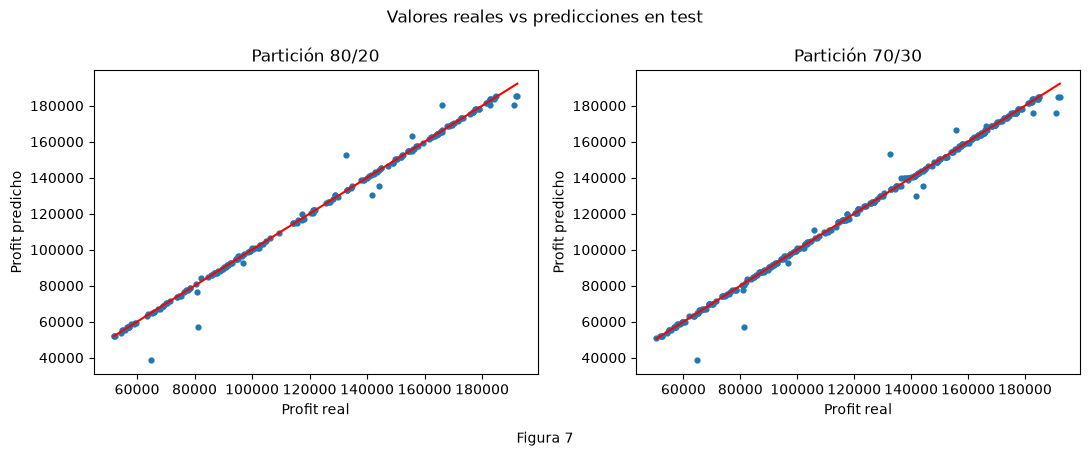

In [14]:
# Valores reales vs predicción
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, nombre in zip(axes, grids_A):
    yte = particiones[nombre][3]
    ax.scatter(yte, preds_A[nombre], s=12)
    ax.plot([yte.min(), yte.max()], [yte.min(), yte.max()], color="red")
    ax.set_title(f"Partición {nombre}")
    ax.set_xlabel("Profit real")
    ax.set_ylabel("Profit predicho")
plt.suptitle("Valores reales vs predicciones en test")
numerar(7)
plt.show()

Figura 7. En ambos test los puntos se alinean sobre la diagonal. Se separan de ella unos pocos puntos (por ejemplo, el de Profit real cercano a 65000 con predicción cercana a 39000), que son los errores grandes que elevan el RMSE por encima del MAE. El gráfico es coherente con la hipótesis de una relación casi lineal y con un MAE bajo. A la escala del gráfico no se distinguen los escalones del árbol.

# Parte B: clasificación (drugType.csv)

## Descripción de las variables de drugType.csv

El conjunto tiene 200 filas, una por paciente, y 6 columnas: cinco características del paciente y el medicamento que se le indicó. La variable objetivo es Droga, con 5 clases. El archivo no incluye un diccionario de datos, por lo que la interpretación de cada columna se apoya en su nombre.

| Variable | Qué representa | Tipo | Rol |
|---|---|---|---|
| Edad | Edad del paciente, en años | Numérica discreta | Predictora |
| Sexo | Sexo del paciente (F o M) | Categórica nominal | Predictora |
| BP | Nivel de presión arterial (Bajo, Normal o Alto) | Categórica ordinal | Predictora |
| Colesterol | Nivel de colesterol (Normal o Alto) | Categórica ordinal | Predictora |
| Na_a_K | Relación entre sodio y potasio en sangre | Numérica continua | Predictora |
| Droga | Medicamento indicado (DrogaA, DrogaB, DrogaC, DrogaX o DrogaY) | Categórica nominal | Objetivo (clasificación) |

## Actividad 3. Preparación de datos

Consigna: hacer el EDA (distribuciones, faltantes, correlaciones y balance de la variable objetivo Droga), limpiar, codificar, estandarizar y generar las particiones 80/20 y 70/30 con random_state=63 y estratificación por Droga.

Usamos el mismo orden que en la Parte A: EDA sobre todo el conjunto y ajuste de transformadores solo con train.

Hipótesis previa: esperamos que Na_a_K sea la variable que mejor separa las clases, que BP y Colesterol aporten reglas adicionales y que Sexo no influya. Esperamos también que las clases no estén parejas.

In [15]:
# Estructura, nulos y categorías
dd = pd.read_csv("drugType.csv")
display(dd.head())
dd.info()
print("Columnas con nulos:", dd.isna().any().sum())
print("Filas duplicadas:", dd.duplicated().sum())
dd.describe()

,Edad,Sexo,BP,Colesterol,Na_a_K,Droga
0,23,F,Alto,Alto,25.355,DrogaY
1,47,M,Bajo,Alto,13.093,DrogaC
2,47,M,Bajo,Alto,10.114,DrogaC
3,28,F,Normal,Alto,7.798,DrogaX
4,61,F,Bajo,Alto,18.043,DrogaY


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Edad        200 non-null    int64  
 1   Sexo        200 non-null    str    
 2   BP          200 non-null    str    
 3   Colesterol  200 non-null    str    
 4   Na_a_K      200 non-null    float64
 5   Droga       200 non-null    str    
dtypes: float64(1), int64(1), str(4)
memory usage: 9.5 KB
Columnas con nulos: 0
Filas duplicadas: 0


,Edad,Na_a_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


,Cantidad,Porcentaje
Droga,,
DrogaY,91,45.5
DrogaX,54,27.0
DrogaA,23,11.5
DrogaC,16,8.0
DrogaB,16,8.0


Razón clase mayoritaria / minoritaria: 5.69


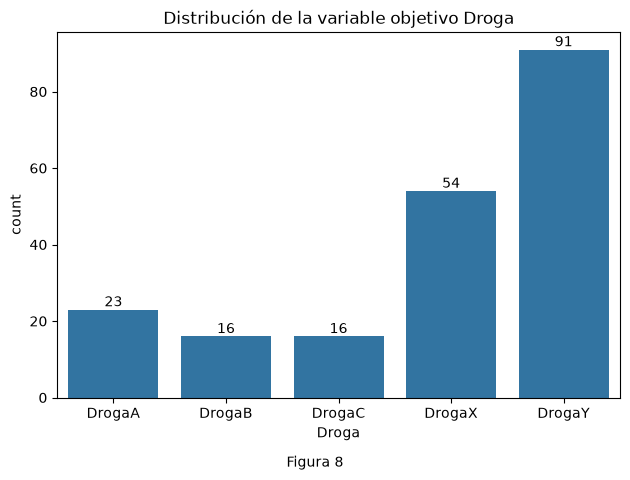

In [16]:
# Balance de clases
cantidad = dd["Droga"].value_counts()
balance = pd.DataFrame({"Cantidad": cantidad, "Porcentaje": (cantidad / len(dd) * 100).round(1)})
display(balance)
print("Razón clase mayoritaria / minoritaria:", round(cantidad.max() / cantidad.min(), 2))

orden = sorted(dd["Droga"].unique())
ax = sns.countplot(data=dd, x="Droga", order=orden)
ax.bar_label(ax.containers[0])
plt.title("Distribución de la variable objetivo Droga")
numerar(8)
plt.show()

Inspección: 200 filas y 6 columnas, sin nulos ni duplicados. Edad va de 15 a 74 y Na_a_K de 6.27 a 38.25.

Figura 8. Las clases están desbalanceadas: DrogaY tiene 91 casos (45.5%), DrogaX 54 (27.0%), DrogaA 23 (11.5%), DrogaB 16 (8.0%) y DrogaC 16 (8.0%). La clase mayoritaria es 5.69 veces la minoritaria. Un modelo que responda siempre DrogaY tendría Accuracy de 0.455 (91 de 200). La hipótesis se cumple.

Decisiones: estratificamos las particiones, como pide la consigna, y evaluamos con Precision y Recall macro, que dan el mismo peso a cada clase, junto con Accuracy. Para elegir hiperparámetros por validación cruzada usamos F1 macro, que combina ambas métricas macro.

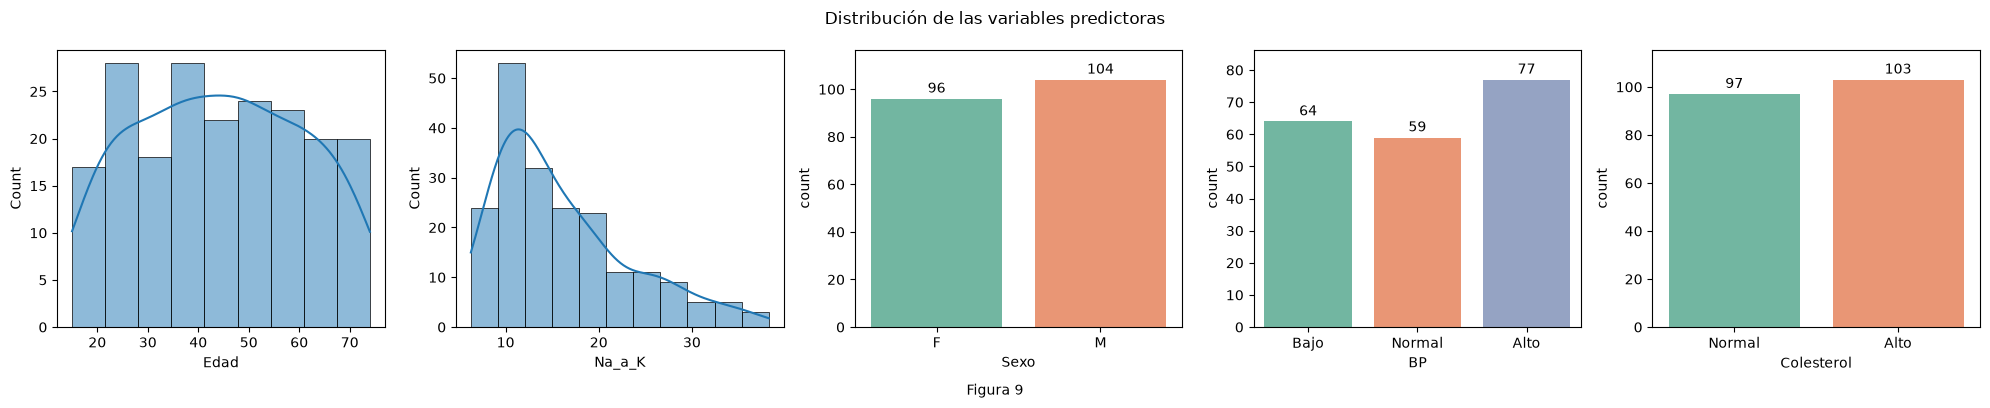

In [17]:
# Distribución de cada variable predictora
ordenes = {"Sexo": ["F", "M"], "BP": ["Bajo", "Normal", "Alto"], "Colesterol": ["Normal", "Alto"]}
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for col, ax in zip(["Edad", "Na_a_K"], axes[:2]):
    sns.histplot(data=dd, x=col, kde=True, edgecolor="black", linewidth=0.5, ax=ax)
for (col, orden_c), ax in zip(ordenes.items(), axes[2:]):
    sns.countplot(data=dd, x=col, order=orden_c, hue=col, hue_order=orden_c, palette="Set2", legend=False, ax=ax)
    for barras in ax.containers:
        ax.bar_label(barras, padding=2)
    ax.margins(y=0.12)
plt.suptitle("Distribución de las variables predictoras")
numerar(9)
plt.show()

Figura 9. Edad se reparte de forma pareja entre 15 y 74 años, con entre 17 y 28 casos por intervalo y sin un pico marcado. Na_a_K se concentra entre 6 y 20, con un máximo cerca de 11, y tiene una cola larga hacia valores altos, hasta 38.25. Las categóricas están parejas: Sexo (F 96 y M 104), BP (Bajo 64, Normal 59 y Alto 77) y Colesterol (Normal 97 y Alto 103). La figura describe cada variable por separado y no permite probar la hipótesis, que trata de la relación con Droga.

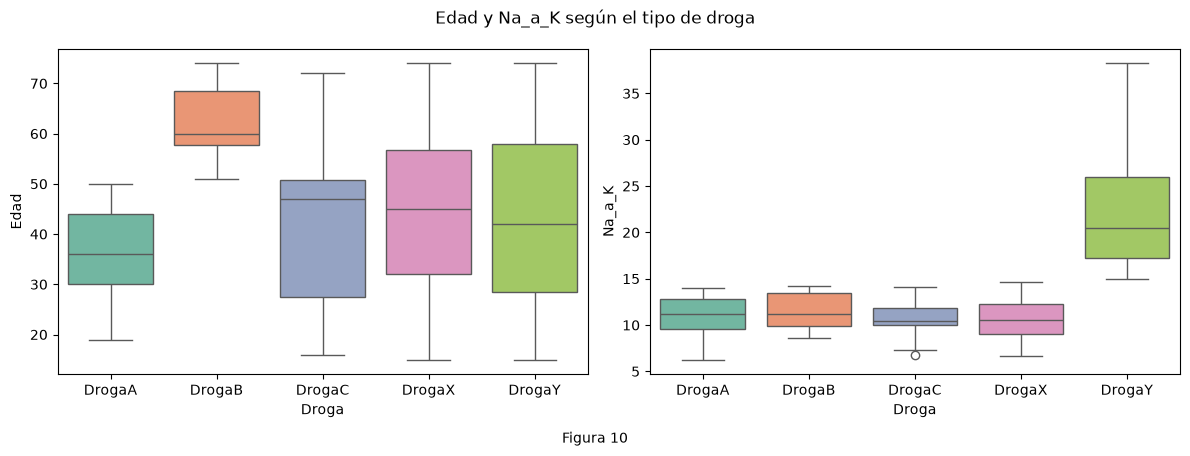

       Edad     Na_a_K       
        min max    min    max
Droga                        
DrogaA   19  50   6.27  13.97
DrogaB   51  74   8.62  14.24
DrogaC   16  72   6.77  14.16
DrogaX   15  74   6.68  14.64
DrogaY   15  74  15.02  38.25 

Droga   DrogaA  DrogaB  DrogaC  DrogaX  DrogaY
BP                                            
Alto        23      16       0       0      38
Bajo         0       0      16      18      30
Normal       0       0       0      36      23 

Droga       DrogaA  DrogaB  DrogaC  DrogaX  DrogaY
Colesterol                                        
Alto            12       8      16      20      47
Normal          11       8       0      34      44 

Droga  DrogaA  DrogaB  DrogaC  DrogaX  DrogaY
Sexo                                         
F           9       6       7      27      47
M          14      10       9      27      44


In [18]:
# Edad y Na_a_K según el tipo de droga, y reglas por categoría
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for col, ax in zip(["Edad", "Na_a_K"], axes):
    sns.boxplot(data=dd, x="Droga", y=col, order=orden, hue="Droga", hue_order=orden, palette="Set2", legend=False, ax=ax)
plt.suptitle("Edad y Na_a_K según el tipo de droga")
numerar(10)
plt.show()

print(dd.groupby("Droga")[["Edad", "Na_a_K"]].agg(["min", "max"]).round(2), "\n")
print(pd.crosstab(dd["BP"], dd["Droga"]), "\n")
print(pd.crosstab(dd["Colesterol"], dd["Droga"]), "\n")
print(pd.crosstab(dd["Sexo"], dd["Droga"]))

Figura 10 y tablas. En el boxplot de Na_a_K, DrogaY queda por encima de las otras cuatro clases (mediana 20.5 contra 10.5 a 11.2): sus valores van de 15.02 a 38.25 y los de las demás no superan 14.64. En el de Edad, DrogaB (mediana 60, de 51 a 74 años) y DrogaA (mediana 36, de 19 a 50) quedan separadas, y DrogaC, DrogaX y DrogaY cubren casi todo el rango, con medianas de 47, 45 y 42.

Las tablas de contingencia muestran reglas por categoría. DrogaA y DrogaB aparecen solo con BP Alto (23 y 16 casos). DrogaC aparece solo con BP Bajo (16 casos) y solo con Colesterol Alto. DrogaX aparece con BP Bajo y Normal (18 y 36) y nunca con BP Alto. Sexo reparte cada clase de forma pareja (DrogaX tiene 27 y 27).

La hipótesis se cumple: Na_a_K es la variable principal, BP y Colesterol aportan reglas y Sexo no influye. Edad, que no habíamos previsto, ayuda a distinguir DrogaA de DrogaB.

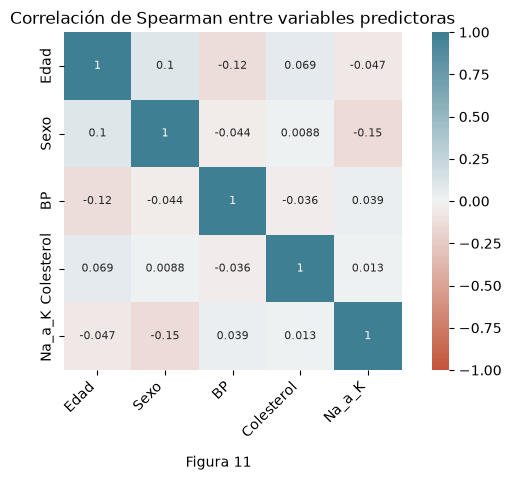

In [19]:
# Correlación de Spearman con variables ordinales codificadas
cat_cols = ["Sexo", "BP", "Colesterol"]
categorias = [["F", "M"], ["Bajo", "Normal", "Alto"], ["Normal", "Alto"]]  # orden natural de BP y Colesterol
dd_cod = dd.drop(columns="Droga").copy()
dd_cod[cat_cols] = OrdinalEncoder(categories=categorias).fit_transform(dd_cod[cat_cols])
plot_correlation_heatmap(dd_cod.corr(method="spearman"), "Correlación de Spearman entre variables predictoras", 11)

Figura 11. Las correlaciones de Spearman entre predictoras tienen valor absoluto de 0.15 o menos. La mayor es la de Sexo con Na_a_K (-0.15). Las predictoras son casi independientes entre sí, lo que favorece a Bayes Ingenuo, que supone independencia entre atributos. Tampoco hay redundancia que eliminar para árboles y k-NN. Excluimos Droga de la matriz porque es nominal.

Codificación: Sexo (F, M), BP (Bajo, Normal, Alto) y Colesterol (Normal, Alto) se codifican con OrdinalEncoder y orden natural explícito.

In [20]:
# Conteo de atípicos por IQR y a qué clase pertenecen
for col in ["Edad", "Na_a_K"]:
    q1, q3 = dd[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (dd[col] < q1 - 1.5 * iqr) | (dd[col] > q3 + 1.5 * iqr)
    print(f"{col}: {mask.sum()} atípicos ({mask.mean() * 100:.1f}%)")
    if mask.sum():
        print("  Clases de los atípicos:", dd.loc[mask, "Droga"].value_counts().to_dict())

Edad: 0 atípicos (0.0%)
Na_a_K: 8 atípicos (4.0%)
  Clases de los atípicos: {'DrogaY': 8}


Atípicos: Edad no tiene ninguno. Na_a_K tiene 8 (4.0%), todos de DrogaY. Revisamos a qué clase pertenecen antes de decidir. Corresponden a los valores altos de DrogaY que muestra la Figura 10, y no hay motivo para considerarlos errores. No los eliminamos: winsorizamos Edad y Na_a_K, que limita cada valor extremo al límite del IQR (fold 1.5). Así se conservan las 8 filas de la clase mayoritaria y los extremos pesan menos en las distancias de k-NN y en la varianza de GaussianNB. Los límites se calculan con train y se aplican también a test. Como no hay nulos ni duplicados, no hace falta otra limpieza.

In [21]:
# Partición estratificada con las dos proporciones del TP
Xd = dd.drop(columns="Droga")
yd = dd["Droga"]
part_B = {}
for nombre, ts in [("80/20", 0.2), ("70/30", 0.3)]:
    part_B[nombre] = train_test_split(Xd, yd, test_size=ts, random_state=SEED, stratify=yd)
conteo = pd.concat({f"{n} {c}": pd.Series(part_B[n][i]).value_counts()
                    for n in part_B for c, i in [("train", 2), ("test", 3)]}, axis=1)
display(conteo)

,80/20 train,80/20 test,70/30 train,70/30 test
Droga,,,,
DrogaY,73,18,64,27
DrogaX,43,11,38,16
DrogaA,18,5,16,7
DrogaC,13,3,11,5
DrogaB,13,3,11,5


In [22]:
# Winsorización de Edad y Na_a_K, codificación ordinal y estandarización, ajustadas solo con train
prep_B = ColumnTransformer([("cat", OrdinalEncoder(categories=categorias), cat_cols),
                            ("num", make_pipeline(Winsorizer(capping_method="iqr", tail="both", fold=1.5), StandardScaler()),
                             ["Edad", "Na_a_K"])],
                           verbose_feature_names_out=False).set_output(transform="pandas")
datos_B = {}
for nombre, (Xtr, Xte, ytr, yte) in part_B.items():
    datos_B[nombre] = (prep_B.fit_transform(Xtr), prep_B.transform(Xte))   # fit solo con train
datos_B["80/20"][0].head()

,Sexo,BP,Colesterol,Edad,Na_a_K
194,0.0,2.0,1.0,0.048965,2.377126
24,0.0,0.0,1.0,-0.734480,2.377126
45,0.0,1.0,0.0,1.254266,-1.119405
114,0.0,1.0,0.0,-1.517926,-0.956230
163,0.0,2.0,0.0,-1.457661,1.733375


Particiones estratificadas: el 80/20 deja 160 filas de train y 40 de test, y el 70/30 deja 140 y 60. Cada clase conserva su proporción. DrogaB, por ejemplo, queda con 13 casos en train y 3 en test (80/20), y con 11 y 5 (70/30). Con 3 a 5 casos de test en las clases chicas, un solo error pesa mucho en el Recall (un error en DrogaB con 3 casos lo baja a 0.67).

Winsorizamos y estandarizamos Edad y Na_a_K, y codificamos Sexo, BP y Colesterol con OrdinalEncoder, todo dentro de un ColumnTransformer ajustado solo con train. El árbol, GaussianNB y k-NN usan estos datos. El Bayes Ingenuo discretizado parte de los datos originales, sin winsorizar, porque los intervalos por cuantiles casi no dependen de los extremos.

## Actividad 4. Árboles de decisión para clasificación

Consigna: estimar Droga con DecisionTreeClassifier, explorar max_depth, min_samples_leaf y min_samples_split con al menos 3 valores cada uno, graficar el árbol antes y después de la post-poda con ccp_alpha, justificar el valor elegido y reportar Precision y Recall macro, Accuracy y la matriz de confusión en ambos test.

La grilla tiene max_depth con 5 valores (2, 3, 4, 5, None), min_samples_leaf con 3 (1, 2, 5) y min_samples_split con 3 (2, 5, 10). Son 45 combinaciones, evaluadas con validación cruzada de 5 folds sobre train y F1 macro.

Hipótesis previa: la raíz del árbol usará Na_a_K, y BP y Colesterol aparecerán en las ramas siguientes (Figura 10). Esperamos un árbol chico, porque las clases se separan con pocas reglas.

In [23]:
# GridSearchCV con los 3 hiperparámetros del TP
param_grid_B = {"max_depth": [2, 3, 4, 5, None],
                "min_samples_leaf": [1, 2, 5],
                "min_samples_split": [2, 5, 10]}
res_B4 = {}
for nombre, (Xtr, Xte) in datos_B.items():
    ytr = part_B[nombre][2]
    g = GridSearchCV(DecisionTreeClassifier(random_state=SEED), param_grid_B, cv=5, scoring="f1_macro").fit(Xtr, ytr)
    r = pd.DataFrame(g.cv_results_)
    res_B4[nombre] = {"params": g.best_params_}
    print(f"Partición {nombre}: mejor = {g.best_params_}, F1 macro CV = {g.best_score_:.3f}, hojas = {g.best_estimator_.get_n_leaves()}, "
          f"configuraciones empatadas en el primer lugar = {(r['rank_test_score'] == 1).sum()} de {len(r)}")
    display(r.groupby("param_max_depth", dropna=False)["mean_test_score"].max().rename("mejor F1 macro CV").round(3).to_frame())

Partición 80/20: mejor = {'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2}, F1 macro CV = 0.966, hojas = 6, configuraciones empatadas en el primer lugar = 27 de 45


,mejor F1 macro CV
param_max_depth,
2.0,0.517
3.0,0.776
4.0,0.966
5.0,0.966
NaN,0.966


Partición 70/30: mejor = {'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2}, F1 macro CV = 0.965, hojas = 6, configuraciones empatadas en el primer lugar = 27 de 45


,mejor F1 macro CV
param_max_depth,
2.0,0.512
3.0,0.761
4.0,0.965
5.0,0.965
NaN,0.965


En cada partición hay 27 configuraciones empatadas en el primer lugar, con F1 macro de validación de 0.966 en el 80/20 y 0.965 en el 70/30. Las profundidades 4, 5 y None alcanzan el mismo valor. La profundidad 2 llega a 0.517 y 0.512, y la 3 a 0.776 y 0.761. El árbol necesita al menos 4 niveles para separar las 5 clases.

GridSearchCV devuelve la primera configuración del empate: max_depth=4, min_samples_leaf=1 y min_samples_split=2 en las dos particiones. Es además la de menos hojas entre las empatadas, con 6, por lo que es el árbol más simple y fácil de interpretar.

In [24]:
for nombre, (Xtr, Xte) in datos_B.items():
    ytr = part_B[nombre][2]
    base = DecisionTreeClassifier(random_state=SEED, **res_B4[nombre]["params"])
    alphas = base.cost_complexity_pruning_path(Xtr, ytr).ccp_alphas
    gp = GridSearchCV(base, {"ccp_alpha": alphas}, cv=5, scoring="f1_macro").fit(Xtr, ytr)
    r = pd.DataFrame(gp.cv_results_)
    r["ccp_alpha"] = r["param_ccp_alpha"].astype(float)
    r["hojas"] = [DecisionTreeClassifier(random_state=SEED, **res_B4[nombre]["params"], ccp_alpha=a).fit(Xtr, ytr).get_n_leaves()
                  for a in r["ccp_alpha"]]
    alpha_sel = r.loc[r["rank_test_score"] == 1, "ccp_alpha"].max()   # desempate: el alpha más grande (árbol más simple)
    res_B4[nombre]["alpha"] = alpha_sel
    print(f"Partición {nombre}: ccp_alpha elegido = {alpha_sel:.4f}")
    display(r[["ccp_alpha", "mean_test_score", "hojas"]].rename(columns={"mean_test_score": "F1 macro CV"}).round(4))

Partición 80/20: ccp_alpha elegido = 0.0000


,ccp_alpha,F1 macro CV,hojas
0,0.0000,0.9656,6
1,0.0624,0.8278,4
2,0.0944,0.5957,3
3,0.1442,0.4396,2
4,0.3304,0.2865,1


Partición 70/30: ccp_alpha elegido = 0.0000


,ccp_alpha,F1 macro CV,hojas
0,0.0000,0.9655,6
1,0.0609,0.9184,4
2,0.0931,0.6620,3
3,0.1454,0.4366,2
4,0.3316,0.2429,1


Poda por complejidad. Para cada partición evaluamos con validación cruzada (F1 macro) los valores de ccp_alpha de la secuencia de poda del árbol elegido. Resultados:

- Partición 80/20: alpha 0 da 0.9656 con 6 hojas. Los siguientes valores dan 0.8278 (4 hojas), 0.5957 (3), 0.4396 (2) y 0.2865 (1).
- Partición 70/30: alpha 0 da 0.9655 con 6 hojas. Los siguientes valores dan 0.9184 (4 hojas), 0.6620 (3), 0.4366 (2) y 0.2429 (1).

Todo alpha mayor que 0 baja el F1 de validación. Elegimos ccp_alpha=0.0 en las dos particiones. La poda no recorta nada, porque la búsqueda de hiperparámetros ya dejó un árbol de 6 hojas, cerca del mínimo para separar 5 clases. Con 4 hojas el árbol no puede predecir las 5 clases. Por eso el árbol antes y después de la poda es el mismo (Figuras 12 y 13).

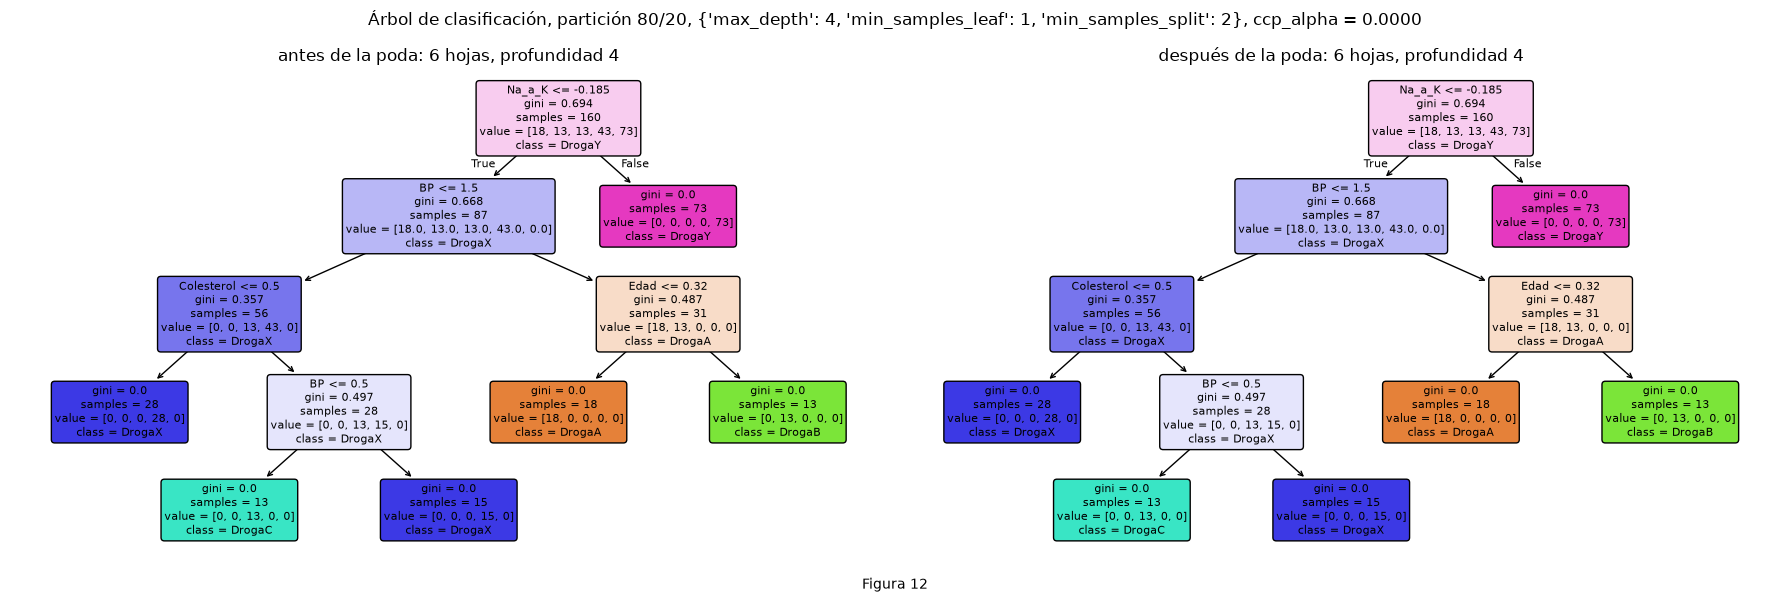

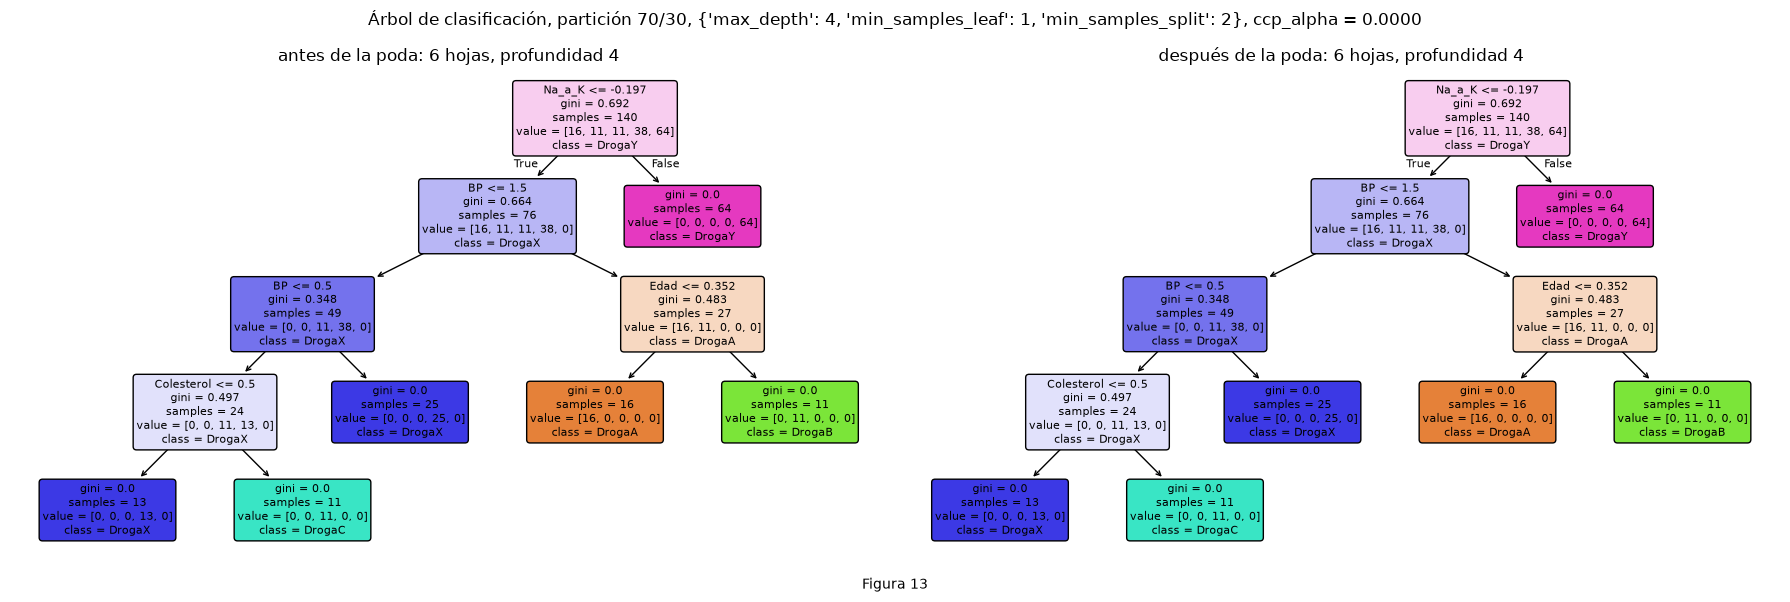

,,Precision macro,Recall macro,Accuracy
Modelo,Partición,,,
Árbol antes de podar,80/20,1.0,1.0,1.0
Árbol podado,80/20,1.0,1.0,1.0
Árbol antes de podar,70/30,1.0,1.0,1.0
Árbol podado,70/30,1.0,1.0,1.0


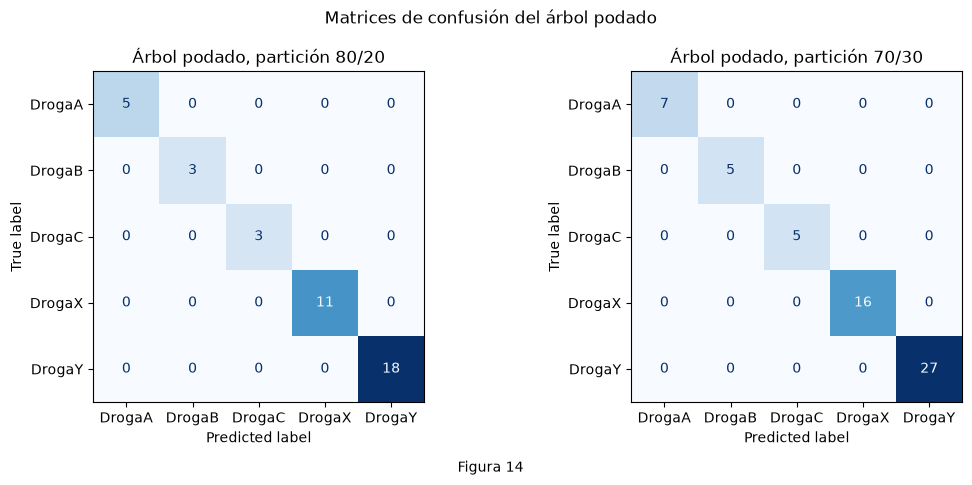

In [25]:
# Árbol antes y después de la post-poda, y métricas sobre ambos test
met_B = {}      # (modelo, partición) -> métricas
preds_B = {}    # (modelo, partición) -> predicciones
for i, nombre in enumerate(part_B, 1):
    Xtr, Xte = datos_B[nombre]
    ytr, yte = part_B[nombre][2], part_B[nombre][3]
    p = res_B4[nombre]["params"]
    antes = DecisionTreeClassifier(random_state=SEED, **p).fit(Xtr, ytr)
    despues = DecisionTreeClassifier(random_state=SEED, **p, ccp_alpha=res_B4[nombre]["alpha"]).fit(Xtr, ytr)
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    for ax, t, tit in [(axes[0], antes, "antes de la poda"), (axes[1], despues, "después de la poda")]:
        plot_tree(t, feature_names=list(Xtr.columns), class_names=list(t.classes_), filled=True, rounded=True,
                  fontsize=8, ax=ax)
        ax.set_title(f"{tit}: {t.get_n_leaves()} hojas, profundidad {t.get_depth()}")
    plt.suptitle(f"Árbol de clasificación, partición {nombre}, {p}, ccp_alpha = {res_B4[nombre]['alpha']:.4f}")
    numerar(11 + i)
    plt.show()
    for etiqueta, t in [("Árbol antes de podar", antes), ("Árbol podado", despues)]:
        preds_B[(etiqueta, nombre)] = t.predict(Xte)
        met_B[(etiqueta, nombre)] = metricas(yte, preds_B[(etiqueta, nombre)])

tabla_B4 = pd.DataFrame({k: v for k, v in met_B.items() if k[0].startswith("Árbol")}).T
tabla_B4.index.names = ["Modelo", "Partición"]
display(tabla_B4.round(3))
plot_cms([(part_B[n][3], preds_B[("Árbol podado", n)], f"Árbol podado, partición {n}") for n in part_B],
         "Matrices de confusión del árbol podado", 14)

Figuras 12 y 13. Los árboles se entrenan con las variables estandarizadas, por lo que los umbrales de Na_a_K y Edad están en desvíos respecto de la media de train. Los dos árboles tienen la raíz en Na_a_K <= -0.185 en el 80/20 y <= -0.197 en el 70/30, que equivalen a 14.829 en unidades originales. La rama derecha es pura de DrogaY (73 casos en el 80/20 y 64 en el 70/30). El umbral queda entre el máximo de las otras clases (14.64) y el mínimo de DrogaY (15.02). En la rama izquierda, BP separa los casos. Con BP Alto, Edad <= 0.320 en el 80/20 y <= 0.352 en el 70/30 (50.5 años) separa a DrogaA de DrogaB. Con BP Bajo o Normal, Colesterol y BP separan a DrogaC de DrogaX, y DrogaC aparece solo con BP Bajo y Colesterol Alto. Las reglas coinciden con las tablas de la Figura 10. La hipótesis se cumple. Edad aparece además como variable para separar DrogaA de DrogaB.

Métricas sobre test: Precision macro, Recall macro y Accuracy valen 1.000 en ambas particiones, antes y después de la poda. La Figura 14 muestra matrices de confusión sin errores (80/20: 5, 3, 3, 11 y 18 casos en la diagonal; 70/30: 7, 5, 5, 16 y 27).

Un resultado de 1.0 sobre 40 y 60 observaciones, con 3 a 5 casos en las clases chicas, es evidencia limitada. Lo leemos como que las reglas aprendidas explican este conjunto. Para datos nuevos haría falta más muestra.

## Actividad 5. Bayes Ingenuo

Consigna: estimar Droga con Naive Bayes, discretizando los atributos continuos por equal-frequency con al menos 3 y 5 intervalos y aplicando CategoricalNB o MultinomialNB. Como alternativa se permite GaussianNB sobre los datos continuos. Reportar Precision y Recall macro, Accuracy y la matriz de confusión en ambos test.

Discretizamos Edad y Na_a_K con KBinsDiscretizer por cuantiles, en 3 y en 5 intervalos. Codificamos los intervalos y las categóricas con one-hot y aplicamos MultinomialNB. Como alternativa usamos GaussianNB sobre los datos estandarizados. El discretizador se ajusta solo con train. Elegimos el mejor de los tres modelos por validación cruzada de 5 folds sobre train, sin mirar el test.

Hipótesis previa: con más intervalos se conserva más información de Na_a_K, por lo que 5 intervalos debería rendir mejor que 3. GaussianNB podría rendir peor, porque Na_a_K de DrogaY es asimétrica (Figura 10).

In [26]:
def nb_discreto(bins):
    return make_pipeline(
        make_column_transformer(
            (KBinsDiscretizer(n_bins=bins, encode="onehot", strategy="quantile"), ["Edad", "Na_a_K"]),
            (OneHotEncoder(), ["Sexo", "BP", "Colesterol"])),
        MultinomialNB())

filas, mejor_nb = [], {}
for nombre in part_B:
    Xtr_raw, Xte_raw, ytr, yte = part_B[nombre]
    Xtr_s, Xte_s = datos_B[nombre]
    candidatos = {"NB discreto, 3 intervalos": (nb_discreto(3), Xtr_raw, Xte_raw),
                  "NB discreto, 5 intervalos": (nb_discreto(5), Xtr_raw, Xte_raw),
                  "GaussianNB": (GaussianNB(), Xtr_s, Xte_s)}
    for etiqueta, (modelo, Xtr_, Xte_) in candidatos.items():
        cv = cross_val_score(modelo, Xtr_, ytr, cv=5, scoring="f1_macro").mean()
        modelo.fit(Xtr_, ytr)
        preds_B[(etiqueta, nombre)] = modelo.predict(Xte_)
        met_B[(etiqueta, nombre)] = metricas(yte, preds_B[(etiqueta, nombre)])
        filas.append({"Partición": nombre, "Modelo": etiqueta, "F1 macro CV (train)": cv, **met_B[(etiqueta, nombre)]})
    # bordes de los intervalos de la partición, para interpretar
    kb = candidatos["NB discreto, 5 intervalos"][0][0].named_transformers_["kbinsdiscretizer"]
    print(nombre, "bordes de los 5 intervalos (Edad, Na_a_K):", [np.round(b, 1).tolist() for b in kb.bin_edges_])
tabla_B5 = pd.DataFrame(filas).set_index(["Partición", "Modelo"])
for nombre in part_B:
    sub = tabla_B5.loc[nombre]["F1 macro CV (train)"]
    mejor_nb[nombre] = sub.idxmax()
display(tabla_B5.round(3))
print("Mejor Naive Bayes por validación cruzada en train:", mejor_nb)

80/20 bordes de los 5 intervalos (Edad, Na_a_K): [[15.0, 28.0, 39.0, 50.0, 61.5, 74.0], [6.3, 9.9, 12.8, 16.1, 22.8, 38.2]]


70/30 bordes de los 5 intervalos (Edad, Na_a_K): [[15.0, 27.0, 38.5, 50.0, 61.0, 74.0], [6.3, 9.8, 12.5, 16.3, 22.9, 38.2]]


F1 macro CV (train)  Precision macro  \
Partición Modelo                                                            
80/20     NB discreto, 3 intervalos                0.691            0.830   
          NB discreto, 5 intervalos                0.811            0.926   
          GaussianNB                               0.813            0.831   
70/30     NB discreto, 3 intervalos                0.639            0.902   
          NB discreto, 5 intervalos                0.766            0.900   
          GaussianNB                               0.843            0.808   

                                     Recall macro  Accuracy  
Partición Modelo                                             
80/20     NB discreto, 3 intervalos         0.811     0.825  
          NB discreto, 5 intervalos         0.967     0.925  
          GaussianNB                        0.933     0.850  
70/30     NB discreto, 3 intervalos         0.830     0.850  
          NB discreto, 5 intervalos         0.963     0.917  
          GaussianNB                        0.933     0.850

Mejor Naive Bayes por validación cruzada en train: {'80/20': 'GaussianNB', '70/30': 'GaussianNB'}


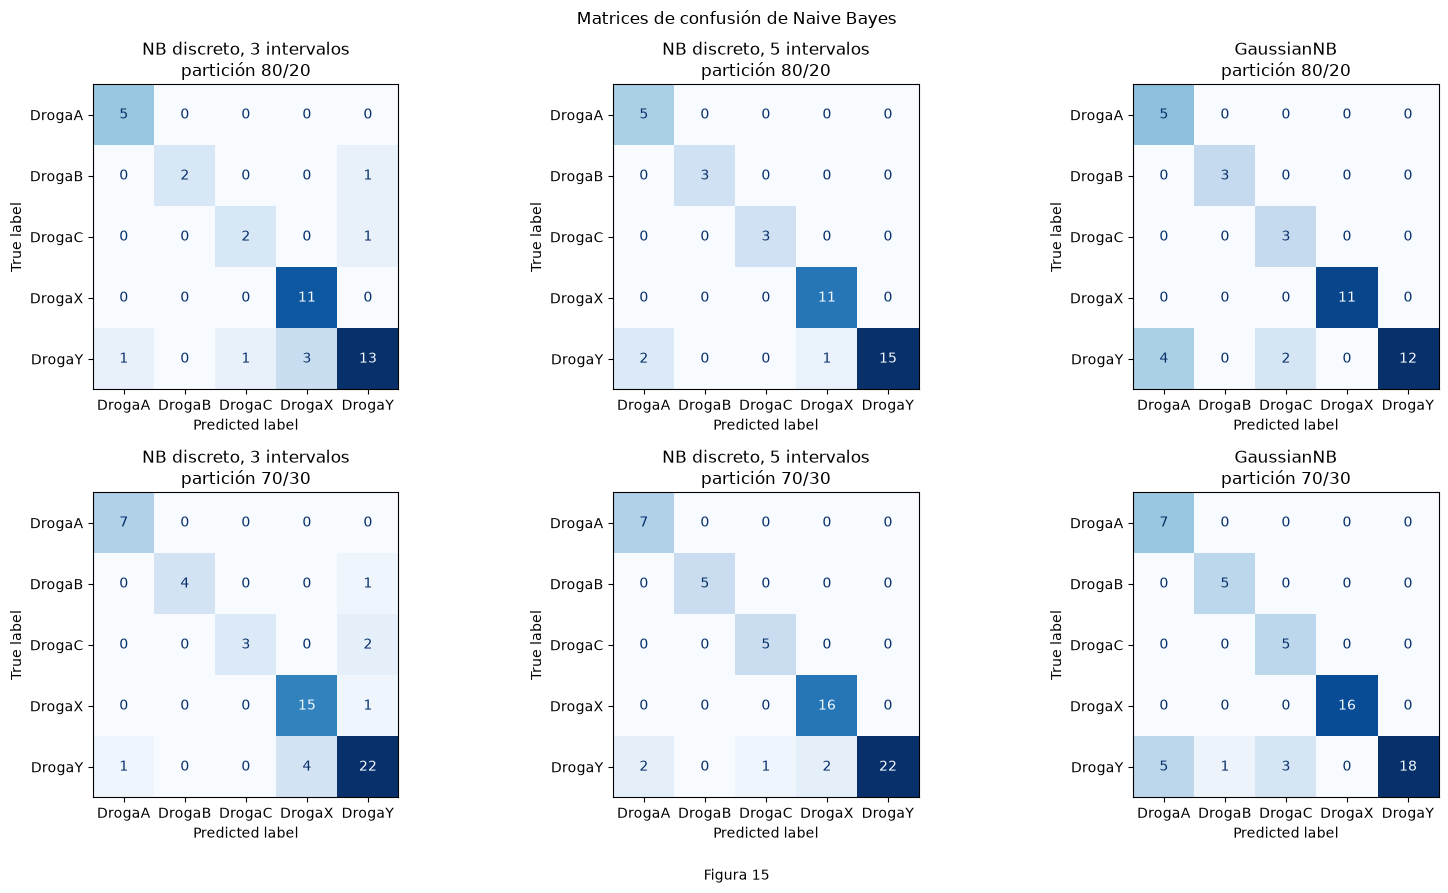

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for fila, nombre in zip(axes, part_B):
    for ax, etiqueta in zip(fila, ["NB discreto, 3 intervalos", "NB discreto, 5 intervalos", "GaussianNB"]):
        ConfusionMatrixDisplay.from_predictions(part_B[nombre][3], preds_B[(etiqueta, nombre)], ax=ax,
                                                cmap="Blues", colorbar=False)
        ax.set_title(f"{etiqueta}\npartición {nombre}")
plt.suptitle("Matrices de confusión de Naive Bayes")
numerar(15)
plt.show()

Bordes de los 5 intervalos en la partición 80/20: Edad [15, 28, 39, 50, 61.5, 74] y Na_a_K [6.3, 9.9, 12.8, 16.1, 22.8, 38.2]. El intervalo de Na_a_K entre 12.8 y 16.1 mezcla casos de DrogaY (desde 15.02) con casos de las otras clases (hasta 14.64). El corte exacto que usó el árbol (14.829 en unidades originales) no existe en esta discretización.

Resultados (F1 macro de validación sobre train, y métricas sobre test):

- 3 intervalos: F1 de validación 0.691 (80/20) y 0.639 (70/30). Accuracy de test 0.825 y 0.850.
- 5 intervalos: F1 de validación 0.811 y 0.766. Accuracy de test 0.925 y 0.917. Recall macro 0.967 y 0.963.
- GaussianNB: F1 de validación 0.813 y 0.843. Accuracy de test 0.850 en ambas particiones. Precision macro 0.831 y 0.808.

Pasar de 3 a 5 intervalos mejora el F1 de validación de 0.691 a 0.811 y de 0.639 a 0.766, como esperábamos. GaussianNB queda primero en la validación cruzada de las dos particiones. En el 80/20 su ventaja sobre 5 intervalos es mínima (0.813 contra 0.811). En el 70/30 es mayor (0.843 contra 0.766). Por eso la hipótesis sobre GaussianNB se cumple solo en parte: en la validación rinde igual o mejor que 5 intervalos, y en test rinde peor en Accuracy (0.850 contra 0.925 y 0.917).

Decisión: elegimos GaussianNB como mejor Bayes Ingenuo, porque seleccionar con los resultados de test no corresponde. La tabla muestra las tres variantes completas.

Figura 15. Los errores se concentran en DrogaY. Con GaussianNB, 6 de 18 casos de DrogaY se clasifican mal en el 80/20 (4 como DrogaA y 2 como DrogaC) y 9 de 27 en el 70/30. Con 5 intervalos los errores de DrogaY bajan a 3 en el 80/20 y 5 en el 70/30. Con GaussianNB y con 5 intervalos, las otras cuatro clases no tienen errores propios. Con 3 intervalos también fallan DrogaB y DrogaC.

## Actividad 6. k-NN

Consigna: estimar Droga con KNeighborsClassifier, explorando n_neighbors (al menos 5 valores) y metric (euclidean, manhattan). Reportar Precision y Recall macro, Accuracy y la matriz de confusión en ambos test.

Usamos validación cruzada de 5 folds sobre train y F1 macro. La grilla tiene n_neighbors en 1, 3, 5, 7 y 9, y metric en euclidean y manhattan (10 combinaciones). Usamos los datos estandarizados, para que Edad y Na_a_K pesen parecido en la distancia. La clase más chica tiene 13 casos en el train del 80/20 y 11 en el del 70/30, y el k máximo (9) queda por debajo.

Hipótesis previa: k-NN separará bien a DrogaY por Na_a_K, pero la distancia trata BP y Colesterol como números ordinales. Esperamos un resultado por debajo del árbol.

In [28]:
# GridSearchCV de k-NN sobre datos estandarizados
# El TP pide metric: euclidean o manhattan
param_grid_knn = {"n_neighbors": [1, 3, 5, 7, 9], "metric": ["euclidean", "manhattan"]}
grids_knn = {}
for nombre in part_B:
    Xtr_s, Xte_s = datos_B[nombre]
    ytr, yte = part_B[nombre][2], part_B[nombre][3]
    grids_knn[nombre] = GridSearchCV(KNeighborsClassifier(), param_grid_knn, cv=5, scoring="f1_macro").fit(Xtr_s, ytr)
    g = grids_knn[nombre]
    preds_B[("k-NN", nombre)] = g.predict(Xte_s)
    met_B[("k-NN", nombre)] = metricas(yte, preds_B[("k-NN", nombre)])
    print(f"Partición {nombre}: mejor = {g.best_params_}, F1 macro CV = {g.best_score_:.3f}, "
          f"clase más chica en train = {ytr.value_counts().min()}")
    r = pd.DataFrame(g.cv_results_)
    display(r.sort_values("rank_test_score")[["rank_test_score", "param_n_neighbors", "param_metric", "mean_test_score"]]
            .rename(columns={"mean_test_score": "F1 macro CV"}).round(3))

Partición 80/20: mejor = {'metric': 'euclidean', 'n_neighbors': 1}, F1 macro CV = 0.862, clase más chica en train = 13


,rank_test_score,param_n_neighbors,param_metric,F1 macro CV
0,1,1,euclidean,0.862
9,2,9,manhattan,0.854
5,3,1,manhattan,0.854
1,4,3,euclidean,0.842
6,5,3,manhattan,0.840
7,6,5,manhattan,0.839
2,7,5,euclidean,0.802
8,8,7,manhattan,0.799
4,9,9,euclidean,0.777
3,10,7,euclidean,0.757


Partición 70/30: mejor = {'metric': 'manhattan', 'n_neighbors': 9}, F1 macro CV = 0.818, clase más chica en train = 11


,rank_test_score,param_n_neighbors,param_metric,F1 macro CV
9,1,9,manhattan,0.818
7,2,5,manhattan,0.787
0,3,1,euclidean,0.777
4,4,9,euclidean,0.767
2,5,5,euclidean,0.763
8,6,7,manhattan,0.750
5,7,1,manhattan,0.741
6,8,3,manhattan,0.729
3,9,7,euclidean,0.718
1,10,3,euclidean,0.699


Precision macro  Recall macro  Accuracy
Modelo Partición                                         
k-NN   80/20                0.813         0.897     0.850
       70/30                0.935         0.930     0.917

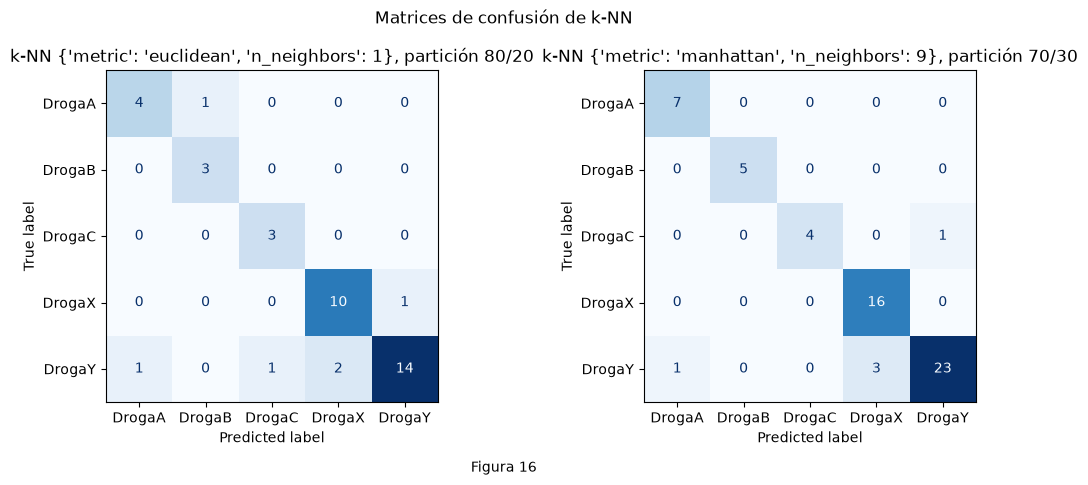

In [29]:
display(pd.DataFrame({k: v for k, v in met_B.items() if k[0] == "k-NN"}).T.rename_axis(["Modelo", "Partición"]).round(3))
plot_cms([(part_B[n][3], preds_B[("k-NN", n)], f"k-NN {grids_knn[n].best_params_}, partición {n}") for n in part_B],
         "Matrices de confusión de k-NN", 16)

Tabla de resultados. La mejor combinación es euclidean con k=1 en el 80/20 (F1 de validación 0.862) y manhattan con k=9 en el 70/30 (0.818). Manhattan supera a euclidean en 3 de los 5 valores de k en el 80/20 y en 4 en el 70/30, por lo que ninguna métrica es claramente mejor. El F1 no sigue una tendencia clara con k: en el 80/20 el máximo está en k=1 y en el 70/30 en k=9. Con 140 a 160 observaciones de train, la elección de k depende de la partición.

Resultados sobre test: en el 80/20, Precision macro 0.813, Recall macro 0.897 y Accuracy 0.850. En el 70/30, 0.935, 0.930 y 0.917.

Figura 16. Los errores del 80/20 son DrogaY clasificada como DrogaX (2 casos), DrogaA (1) y DrogaC (1), un DrogaX clasificado como DrogaY y un DrogaA clasificado como DrogaB. En el 70/30 son DrogaY como DrogaX (3) y DrogaA (1), y un DrogaC como DrogaY. DrogaB no tiene errores de Recall en ninguna partición. La hipótesis se cumple: k-NN queda por debajo del árbol (Accuracy 0.850 y 0.917 contra 1.0).

## Actividad 7. Comparación de modelos

Consigna: comparar el mejor modelo de cada algoritmo (árbol de decisión, Bayes Ingenuo y k-NN) sobre ambos test, y elegir y justificar el más adecuado según las métricas y la interpretabilidad.

La tabla reúne el árbol podado (igual al no podado, ver Actividad 4), el Bayes Ingenuo elegido por validación cruzada (GaussianNB) y el k-NN de la Actividad 6.

In [30]:
# Tabla comparativa: mejor modelo de cada algoritmo
final = []
for nombre in part_B:
    for algoritmo, clave in [("Árbol de decisión (podado)", "Árbol podado"),
                             (f"Bayes Ingenuo ({mejor_nb[nombre]})", mejor_nb[nombre]),
                             ("k-NN", "k-NN")]:
        final.append({"Partición": nombre, "Algoritmo": algoritmo, **met_B[(clave, nombre)]})
comparacion = pd.DataFrame(final).set_index(["Partición", "Algoritmo"])
display(comparacion.round(3))

Precision macro  Recall macro  Accuracy
Partición Algoritmo                                                          
80/20     Árbol de decisión (podado)            1.000         1.000     1.000
          Bayes Ingenuo (GaussianNB)            0.831         0.933     0.850
          k-NN                                  0.813         0.897     0.850
70/30     Árbol de decisión (podado)            1.000         1.000     1.000
          Bayes Ingenuo (GaussianNB)            0.808         0.933     0.850
          k-NN                                  0.935         0.930     0.917

Resultados (Precision macro, Recall macro y Accuracy):

- Árbol de decisión: 1.000, 1.000 y 1.000 en ambos test.
- k-NN: 0.813, 0.897 y 0.850 en el 80/20, y 0.935, 0.930 y 0.917 en el 70/30.
- Bayes Ingenuo (GaussianNB): 0.831, 0.933 y 0.850 en el 80/20, y 0.808, 0.933 y 0.850 en el 70/30.

Elegimos el árbol de decisión por estas razones:

- Tiene las mejores métricas en ambos test y es el único modelo sin errores en las matrices de confusión.
- Es interpretable: sus 6 reglas usan 4 atributos (Na_a_K, BP, Colesterol y Edad) y se leen directamente en las Figuras 12 y 13. Coinciden con lo que mostró el EDA.
- k-NN no entrega reglas que expliquen cada predicción y su F1 de validación (0.862 y 0.818) es menor que el del árbol (0.966 y 0.965).
- Bayes Ingenuo es simple y rápido, pero queda por debajo del árbol en las tres métricas.

Limitaciones: los test tienen 40 y 60 observaciones, con 3 a 5 casos en las clases chicas, por lo que un 1.0 no garantiza el mismo resultado con datos nuevos. Los árboles de las dos particiones usan el mismo umbral de Na_a_K (14.829 en unidades originales) y las mismas variables, lo que sugiere reglas estables.

# Conclusiones

Parte A (regresión):

- Eliminamos 3 filas anómalas de Profit y una fila duplicada.
- El mejor árbol (max_depth=10, min_samples_leaf=5 y min_samples_split=2) logra MAE de 1098.9 y 942.6, y RMSE de 3496.1 y 2929.1 en los test 80/20 y 70/30.
- RyD_Spend domina los primeros cortes, en coincidencia con su correlación de 0.999 con Profit. Administration tiene correlación moderada (0.745) y casi no interviene en el árbol.

Parte B (clasificación):

- Droga está desbalanceada (la clase mayoritaria es 5.69 veces la minoritaria). Estratificamos las particiones y usamos métricas macro.
- Na_a_K separa a DrogaY. BP, Colesterol y Edad separan las demás clases. El árbol de 6 hojas lo refleja y alcanza 1.000 en Precision macro, Recall macro y Accuracy en ambos test.
- La validación cruzada eligió ccp_alpha=0.0. La poda por complejidad bajó el F1 de validación en todos los valores positivos, y el árbol antes y después de podar es el mismo.
- En Bayes Ingenuo, 5 intervalos rinden mejor que 3. GaussianNB ganó la validación cruzada y alcanzó Accuracy de 0.850 en ambos test. Con 5 intervalos el Accuracy de test fue 0.925 y 0.917.
- k-NN alcanzó Accuracy de 0.850 (euclidean, k=1) y 0.917 (manhattan, k=9). La métrica y el k cambiaron con la partición.
- Elegimos el árbol de decisión por sus métricas y por la claridad de sus reglas.

Puntos a tener en cuenta: los test son chicos y la selección de hiperparámetros se apoya en validación cruzada sobre train, con una sola semilla (63). Con más datos conviene repetir la comparación.